# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** Patrick Rostand Gandjouon Tchassem
**Date:** 10/15/2026
**GitHub Repository:** https://github.com/PatRost/ITAI2373-NewsBot-Midterm

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [35]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 51.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All packages installed successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [36]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [37]:

# Module 1: Load and Explore the BBC News Dataset

# Import pandas to work with the dataset
import pandas as pd

# Load the BBC News training dataset downloaded from Kaggle
# Load the BBC News training dataset uploaded to Colab
df = pd.read_csv("BBC_News_Train[1].csv")

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display the column names to understand the dataset structure
print("Columns:", df.columns.tolist())

# Display the first five rows to preview the news articles
print("\nFirst five rows:")
display(df.head())

# Display the number of articles in each news category
print("\nNews categories and article counts:")
print(df["Category"].value_counts())

# Check for missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (1490, 3)
Columns: ['ArticleId', 'Text', 'Category']

First five rows:


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business



News categories and article counts:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64


In [38]:

# Module 1: Prepare the dataset for NLP processing

# Create a copy to keep the original dataset unchanged
df = df.copy()

# Rename columns so they are consistent across modules
df = df.rename(columns={
    "Text": "content",
    "Category": "category"
})

# Remove duplicate articles to improve data quality
df = df.drop_duplicates(subset=["content"])

# Remove any empty text or category records
df = df.dropna(subset=["content", "category"])

# Display the prepared dataset information
print("Prepared dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Check that the categories are still available
print("\nCategory distribution:")
print(df["category"].value_counts())

# Save a clean copy for later use
df.to_csv("newsbot_dataset.csv", index=False)

print("\nDataset preparation completed successfully!")


Prepared dataset shape: (1440, 3)
Columns: ['ArticleId', 'content', 'category']

Category distribution:
category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64

Dataset preparation completed successfully!


In [39]:

# Module 1: Basic Dataset Exploration

# Display the dataset overview
print("📊 DATASET OVERVIEW")
print("=" * 50)

# Display the total number of articles
print(f"Total articles: {len(df)}")

# Display the number of unique news categories
print(f"Unique categories: {df['category'].nunique()}")

# Display the names of the news categories
print(f"Categories: {df['category'].unique().tolist()}")

# Display the number of articles in each category
print("\nArticles per category:")
print(df['category'].value_counts())

# Calculate the number of words in each article
df['word_count'] = df['content'].astype(str).apply(
    lambda text: len(text.split())
)

# Display basic article length statistics
print("\nArticle length statistics:")
print(df['word_count'].describe())

# Check for missing values
print("\nMissing values:")
print(df[['content', 'category']].isnull().sum())

# Check whether the dataset contains a date column
if 'date' in df.columns:
    print("\nDate range:")
    print(df['date'].min(), "to", df['date'].max())
else:
    print("\nDate information is not available in this dataset.")

# Display the first five articles
print("\nFirst five articles:")
display(df[['category', 'content', 'word_count']].head())


# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues

📊 DATASET OVERVIEW
Total articles: 1440
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

Articles per category:
category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64

Article length statistics:
count    1440.000000
mean      385.215972
std       212.167106
min        90.000000
25%       253.000000
50%       337.000000
75%       468.250000
max      3345.000000
Name: word_count, dtype: float64

Missing values:
content     0
category    0
dtype: int64

Date information is not available in this dataset.

First five articles:


,category,content,word_count
0,business,worldcom ex-boss launches defence lawyers defe...,301
1,business,german business confidence slides german busin...,325
2,business,bbc poll indicates economic gloom citizens in ...,514
3,tech,lifestyle governs mobile choice faster bett...,634
4,business,enron bosses in $168m payout eighteen former e...,355


**Dataset Preparation Summary**

We downloaded the BBC News Classification dataset from Kaggle. The original dataset contained 1,490 news articles across five categories: Sport, Business, Politics, Entertainment, and Technology.

After removing duplicate articles, we had 1,440 articles remaining. We also renamed the columns to make them easier to use in the NLP pipeline. The dataset is now ready for preprocessing, feature extraction, sentiment analysis, and classification.

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [40]:

# Module 2: Advanced Text Preprocessing

# Import libraries for text cleaning and processing
import re
import html
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk

# Download the required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

# Initialize the lemmatizer and English stop words
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Create a function to clean news article text
def clean_text(text):

    # Return an empty string if the text is missing
    if pd.isna(text):
        return ""

    # Convert the text to lowercase
    text = str(text).lower()

    # Convert HTML entities into normal characters
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove website URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove numbers, punctuation, and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Return the cleaned text
    return text


# Create a function for the complete preprocessing pipeline
def preprocess_text(text, remove_stopwords=True, lemmatize=True):

    # Clean the original text
    text = clean_text(text)

    # Return an empty string if no text remains
    if not text:
        return ""

    # Break the text into individual words
    tokens = word_tokenize(text)

    # Remove common English stop words
    if remove_stopwords:
        tokens = [word for word in tokens if word not in stop_words]

    # Convert words to their base forms
    if lemmatize:
        tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Remove words containing two or fewer characters
    tokens = [word for word in tokens if len(word) > 2]

    # Combine the processed words into a string
    return ' '.join(tokens)


# Test the functions using a sample sentence
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"

# Display the original text
print("Original text:")
print(sample_text)

# Display the cleaned text
print("\nCleaned text:")
print(clean_text(sample_text))

# Display the fully processed text
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [41]:

# Module 2: Apply Text Preprocessing to All News Articles

# Display a message before processing starts
print("🧹 Preprocessing all BBC News articles...")

# Create a new column containing cleaned article text
df['content_clean'] = df['content'].apply(clean_text)

# Create another column containing fully preprocessed text
df['content_processed'] = df['content'].apply(preprocess_text)

# Calculate the number of words in the original articles
df['original_word_count'] = df['content'].apply(
    lambda text: len(str(text).split())
)

# Calculate the number of words after preprocessing
df['processed_word_count'] = df['content_processed'].apply(
    lambda text: len(text.split())
)

# Display the number of articles processed
print(f"\nTotal articles processed: {len(df)}")

# Display the average word count before preprocessing
print(f"Average original words: {df['original_word_count'].mean():.2f}")

# Display the average word count after preprocessing
print(f"Average processed words: {df['processed_word_count'].mean():.2f}")

# Display a sample of the processed dataset
print("\nSample processed articles:")
display(df[['category', 'content_clean', 'content_processed']].head())

# Save the processed dataset for later NLP modules
df.to_csv("newsbot_preprocessed.csv", index=False)

print("\nText preprocessing completed successfully!")


🧹 Preprocessing all BBC News articles...

Total articles processed: 1440
Average original words: 385.22
Average processed words: 209.69

Sample processed articles:


,category,content_clean,content_processed
0,business,worldcom ex boss launches defence lawyers defe...,worldcom bos launch defence lawyer defending f...
1,business,german business confidence slides german busin...,german business confidence slide german busine...
2,business,bbc poll indicates economic gloom citizens in ...,bbc poll indicates economic gloom citizen majo...
3,tech,lifestyle governs mobile choice faster better ...,lifestyle governs mobile choice faster better ...
4,business,enron bosses in m payout eighteen former enron...,enron boss payout eighteen former enron direct...



Text preprocessing completed successfully!


### Module 2: Text Preprocessing Analysis

We successfully preprocessed all 1,440 BBC News articles. The average article length decreased from 385.22 words to 209.69 words, a reduction of approximately 45.6%.

During preprocessing, we converted text to lowercase, removed unnecessary characters and stop words, and applied lemmatization. These steps helped make the articles more consistent for feature extraction and machine learning.

One challenge is that preprocessing can remove useful information, such as numbers or short words. For this reason, we kept the original article text for other NLP tasks, including sentiment analysis and named entity recognition.

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [42]:

# Module 3: TF-IDF Feature Extraction

# Import the TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF vectorizer using the professor's settings
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,   # Limit vocabulary to 5,000 features
    ngram_range=(1, 2),  # Include single words and two-word phrases
    min_df=2,            # Ignore terms appearing in fewer than 2 articles
    max_df=0.8           # Ignore terms appearing in more than 80% of articles
)

# Convert the processed articles into numerical TF-IDF features
print("Creating TF-IDF features...")

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df['content_processed']
)

# Get the vocabulary terms
feature_names = tfidf_vectorizer.get_feature_names_out()

# Display the TF-IDF matrix dimensions
print("TF-IDF matrix shape:", tfidf_matrix.shape)

# Display the number of extracted features
print("Total TF-IDF features:", len(feature_names))

# Display the first 20 vocabulary terms
print("\nFirst 20 vocabulary terms:")
print(feature_names[:20])

# Display a success message
print("\nTF-IDF feature extraction completed successfully!")


Creating TF-IDF features...
TF-IDF matrix shape: (1440, 5000)
Total TF-IDF features: 5000

First 20 vocabulary terms:
['abbas' 'abc' 'ability' 'able' 'abroad' 'absence' 'absolute' 'absolutely'
 'abuse' 'abused' 'academy' 'academy award' 'accept' 'acceptable'
 'accepted' 'accepting' 'access' 'accessible' 'accident' 'accolade']

TF-IDF feature extraction completed successfully!


In [43]:

# Module 3: Analyze Important TF-IDF Terms by Category

# Import NumPy for numerical operations
import numpy as np

# Create a function to find important terms for each category
def get_top_tfidf_terms(category, n_terms=10):

    # Find the positions of articles belonging to the category
    category_indices = np.where(
        df['category'].to_numpy() == category
    )[0]

    # Return an empty list if the category is not found
    if len(category_indices) == 0:
        return []

    # Select TF-IDF rows for the chosen category
    category_matrix = tfidf_matrix[category_indices]

    # Calculate the average TF-IDF score for each term
    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    # Find the terms with the highest average scores
    top_indices = np.argsort(mean_scores)[::-1][:n_terms]

    # Return the important terms and their scores
    return [
        (feature_names[i], float(mean_scores[i]))
        for i in top_indices
    ]


# Display the top 10 terms for each news category
for category in sorted(df['category'].unique()):

    print(f"\nTop 10 TF-IDF terms for {category.upper()}:")
    print("-" * 45)

    # Get the important terms for this category
    top_terms = get_top_tfidf_terms(category, 10)

    # Display each term and its average TF-IDF score
    for term, score in top_terms:
        print(f"{term}: {score:.4f}")



Top 10 TF-IDF terms for BUSINESS:
---------------------------------------------
firm: 0.0388
company: 0.0371
market: 0.0345
year: 0.0329
bank: 0.0326
growth: 0.0325
sale: 0.0316
economy: 0.0314
share: 0.0309
profit: 0.0274

Top 10 TF-IDF terms for ENTERTAINMENT:
---------------------------------------------
film: 0.1015
award: 0.0536
best: 0.0477
star: 0.0394
show: 0.0378
music: 0.0359
actor: 0.0336
band: 0.0333
year: 0.0316
oscar: 0.0304

Top 10 TF-IDF terms for POLITICS:
---------------------------------------------
labour: 0.0639
election: 0.0620
blair: 0.0556
party: 0.0523
tory: 0.0459
government: 0.0452
would: 0.0447
minister: 0.0425
brown: 0.0381
tax: 0.0329

Top 10 TF-IDF terms for SPORT:
---------------------------------------------
game: 0.0449
england: 0.0369
win: 0.0337
player: 0.0321
match: 0.0317
champion: 0.0289
team: 0.0279
cup: 0.0279
final: 0.0263
injury: 0.0256

Top 10 TF-IDF terms for TECH:
---------------------------------------------
mobile: 0.0522
phone: 0.0472
p

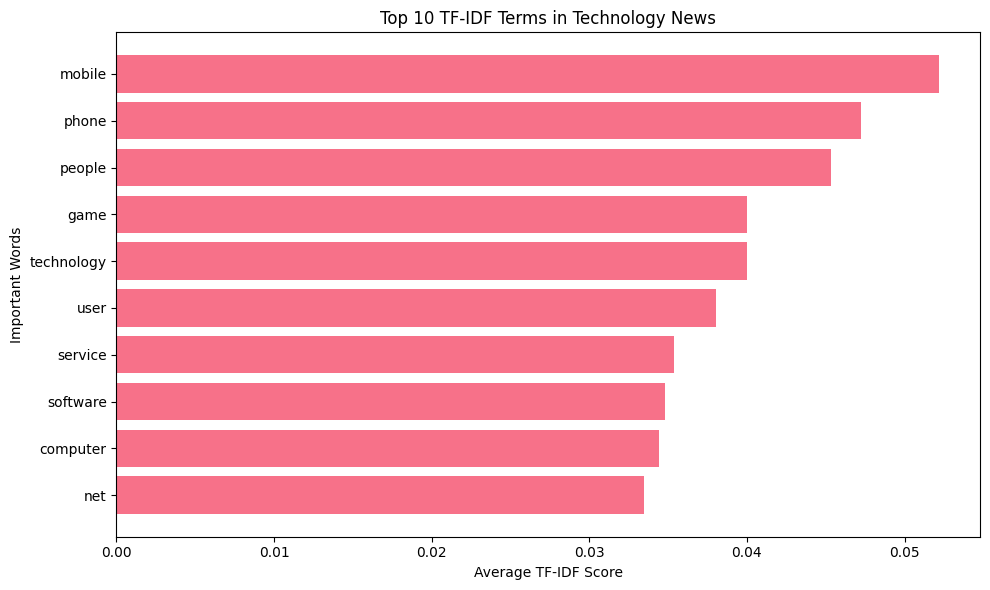

In [44]:

# Module 3: Visualize Important TF-IDF Terms

# Import libraries for charts
import matplotlib.pyplot as plt

# Select the Technology category for visualization
category = "tech"

# Get the top 10 TF-IDF terms and their scores
top_terms = get_top_tfidf_terms(category, 10)

# Separate the words and scores
words = [term for term, score in top_terms]
scores = [score for term, score in top_terms]

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

# Display the TF-IDF scores for each word
plt.barh(words, scores)

# Place the highest-scoring word at the top
plt.gca().invert_yaxis()

# Add a title and axis labels
plt.title("Top 10 TF-IDF Terms in Technology News")
plt.xlabel("Average TF-IDF Score")
plt.ylabel("Important Words")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()


### Module 3: TF-IDF Analysis

In this module, we used TF-IDF to convert 1,440 news articles into 5,000 numerical features. We also identified the most important terms in each news category.

The results showed that different categories contain different important words. For example, Technology articles included words such as "mobile," "phone," "software," and "computer." Sports articles included words such as "player," "match," "champion," and "team."

This shows how TF-IDF can help NewsBot identify patterns in news articles and support automatic classification. However, some words may appear in multiple categories, so TF-IDF alone does not guarantee a correct classification.

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [45]:

# Module 4: Part-of-Speech (POS) Analysis

# Import libraries needed for POS tagging
import nltk
import pandas as pd
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk import pos_tag

# Download the required NLTK resources
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Create a function to analyze grammatical patterns
def analyze_pos_patterns(text):

    # Check for missing or empty text
    if pd.isna(text) or not str(text).strip():
        return {}

    # Break the original article into individual words
    tokens = word_tokenize(str(text))

    # Keep only word tokens, excluding punctuation
    tokens = [word for word in tokens if any(c.isalpha() for c in word)]

    # Return an empty result if no words are found
    if not tokens:
        return {}

    # Assign a grammatical tag to each word
    pos_tags = pos_tag(tokens)

    # Count how many times each POS tag appears
    pos_counts = Counter(tag for word, tag in pos_tags)

    # Calculate the total number of tagged words
    total_words = len(pos_tags)

    # Convert the counts into proportions
    pos_proportions = {
        tag: count / total_words
        for tag, count in pos_counts.items()
    }

    # Return the grammatical proportions
    return pos_proportions


# Test the function using an original BBC News article
sample_article = df['content'].iloc[0]

# Analyze the first 500 characters for a quick test
sample_pos = analyze_pos_patterns(sample_article[:500])

# Display the grammatical patterns
print("POS analysis for the sample article:")
for tag, proportion in sorted(
    sample_pos.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{tag}: {proportion:.3f}")

print("\nPOS analysis completed successfully!")


POS analysis for the sample article:
NN: 0.329
NNS: 0.132
IN: 0.118
DT: 0.092
JJ: 0.079
VBN: 0.039
TO: 0.039
VBG: 0.026
PRP$: 0.026
VBD: 0.026
VBP: 0.013
VB: 0.013
PRP: 0.013
CD: 0.013
VBZ: 0.013
RB: 0.013
CC: 0.013

POS analysis completed successfully!


Analyzing POS patterns by category...

Average POS proportions by category:


,NN,NNS,NNP,NNPS,VB,VBD,VBG,VBN,VBP,VBZ,JJ,JJR,JJS
category,,,,,,,,,,,,,
business,0.234,0.081,0.001,0.0,0.036,0.046,0.022,0.031,0.020,0.027,0.100,0.005,0.004
entertainment,0.259,0.062,0.001,0.0,0.031,0.050,0.021,0.032,0.022,0.025,0.100,0.003,0.005
politics,0.218,0.072,0.001,0.0,0.047,0.050,0.022,0.032,0.024,0.025,0.095,0.003,0.002
sport,0.234,0.051,0.001,0.0,0.041,0.050,0.019,0.027,0.030,0.027,0.104,0.002,0.002
tech,0.201,0.091,0.001,0.0,0.045,0.032,0.026,0.029,0.027,0.032,0.098,0.006,0.003



POS category comparison:


,Nouns,Verbs,Adjectives,Proper Nouns
category,,,,
business,0.316,0.182,0.108,0.001
entertainment,0.322,0.181,0.108,0.001
politics,0.291,0.200,0.100,0.001
sport,0.286,0.193,0.108,0.001
tech,0.292,0.191,0.106,0.001


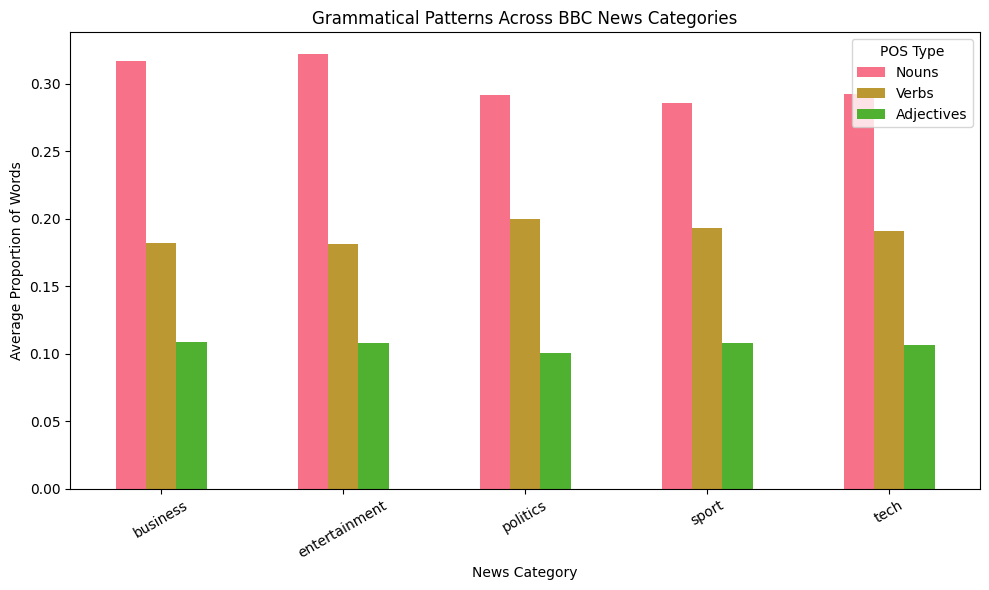


POS category analysis completed successfully!


In [46]:

# Module 4: Compare POS Patterns Across News Categories

# Import libraries for data analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt

# Display a message before starting
print("Analyzing POS patterns by category...")

# Create a list to store the results
pos_results = []

# Analyze each article using its original text
for _, row in df.iterrows():

    # Get the grammatical proportions for this article
    pos_patterns = analyze_pos_patterns(row['content'])

    # Add the article category to the results
    pos_patterns['category'] = row['category']

    # Store the result
    pos_results.append(pos_patterns)

# Convert the results into a DataFrame
pos_df = pd.DataFrame(pos_results)

# Replace missing POS values with zero
pos_df = pos_df.fillna(0)

# Calculate the average POS proportions for each category
pos_by_category = pos_df.groupby('category').mean(
    numeric_only=True
)

# Select common grammatical tags for comparison
selected_tags = [
    'NN', 'NNS', 'NNP', 'NNPS',
    'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
    'JJ', 'JJR', 'JJS'
]

# Keep only tags that appear in the results
available_tags = [
    tag for tag in selected_tags
    if tag in pos_by_category.columns
]

# Display the average grammatical patterns
print("\nAverage POS proportions by category:")
display(pos_by_category[available_tags].round(3))

# Create grouped POS categories for easier comparison
pos_summary = pd.DataFrame(index=pos_by_category.index)

# Combine common and proper nouns
pos_summary['Nouns'] = pos_by_category.reindex(
    columns=['NN', 'NNS', 'NNP', 'NNPS'],
    fill_value=0
).sum(axis=1)

# Combine different verb forms
pos_summary['Verbs'] = pos_by_category.reindex(
    columns=['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'],
    fill_value=0
).sum(axis=1)

# Combine adjective forms
pos_summary['Adjectives'] = pos_by_category.reindex(
    columns=['JJ', 'JJR', 'JJS'],
    fill_value=0
).sum(axis=1)

# Calculate the proportion of proper nouns
pos_summary['Proper Nouns'] = pos_by_category.reindex(
    columns=['NNP', 'NNPS'],
    fill_value=0
).sum(axis=1)

# Display the summary table
print("\nPOS category comparison:")
display(pos_summary.round(3))

# Create a bar chart comparing grammatical patterns
pos_summary[['Nouns', 'Verbs', 'Adjectives']].plot(
    kind='bar',
    figsize=(10, 6)
)

# Add chart labels
plt.title("Grammatical Patterns Across BBC News Categories")
plt.xlabel("News Category")
plt.ylabel("Average Proportion of Words")
plt.xticks(rotation=30)
plt.legend(title="POS Type")

# Display the chart
plt.tight_layout()
plt.show()

print("\nPOS category analysis completed successfully!")


### Module 4: Part-of-Speech Analysis

In this module, we used POS tagging to analyze grammatical patterns across the five BBC News categories. We compared the average proportions of nouns, verbs, and adjectives in the articles.

The results showed that nouns were the most common grammatical category across all five news categories. Politics articles appeared to have a slightly higher proportion of verbs than Sports articles, while adjective usage was relatively similar across the categories.

Our original hypothesis suggested that Sports articles might contain more action verbs. However, the results did not clearly support this prediction because Politics had a slightly higher overall verb proportion. This analysis helped us understand how grammatical patterns can vary across different types of news articles.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [47]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features


# Module 5: Apply Syntactic Analysis to Sample Articles

# Display a message before starting the analysis
print("Performing syntactic analysis...")

# Create a list to store the results
syntactic_results = []

# Analyze the first five BBC News articles
for idx, row in df.head(5).iterrows():

    # Use the original article text to preserve sentence structure
    features = extract_syntactic_features(row['content'])

    # Store the news category
    features['category'] = row['category']

    # Store the article identifier
    features['article_id'] = row['ArticleId']

    # Add the results to our list
    syntactic_results.append(features)

# Confirm that the analysis is complete
print("\nSyntactic analysis complete!")

# Display the results for each article
for i, result in enumerate(syntactic_results):

    # Display the article number and category
    print(f"\nArticle {i+1} ({result['category']}):")

    # Display the number of sentences and tokens
    print(f"Sentences: {result['num_sentences']}")
    print(f"Tokens: {result['num_tokens']}")

    # Display the first three noun phrases
    print(f"Noun phrases: {result['noun_phrases'][:3]}")

    # Display the first three subjects
    print(f"Subjects: {result['subjects'][:3]}")

    # Display the first three objects
    print(f"Objects: {result['objects'][:3]}")

    # Display the most common dependency relationships
    print("Top dependency relations:")
    top_dependencies = sorted(
        result['dependency_counts'].items(),
        key=lambda item: item[1],
        reverse=True
    )[:5]

    for relation, count in top_dependencies:
        print(f"  {relation}: {count}")


Performing syntactic analysis...

Syntactic analysis complete!

Article 1 (business):
Sentences: 15
Tokens: 346
Noun phrases: ['-', 'boss', 'defence lawyers']
Subjects: ['-', 'boss', 'worldcom']
Objects: ['lawyers', 'ebbers', 'battery']
Top dependency relations:
  compound: 43
  pobj: 35
  prep: 33
  nsubj: 26
  dobj: 22

Article 2 (business):
Sentences: 15
Tokens: 368
Noun phrases: ['german business confidence', 'german business confidence', 'february']
Subjects: ['confidence', 'ifo', 'index']
Objects: ['confidence', 'february', 'hopes']
Top dependency relations:
  prep: 38
  pobj: 35
  nsubj: 31
  amod: 29
  compound: 29

Article 3 (business):
Sentences: 24
Tokens: 587
Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']
Subjects: ['poll', 'citizens', 'economy']
Objects: ['majority', 'nations', 'poll']
Top dependency relations:
  prep: 64
  pobj: 60
  det: 48
  nsubj: 47
  amod: 29

Article 4 (tech):
Sentences: 31
Tokens: 724
Noun phrases: ['lifestyle', 'mobile choice'

In [48]:

# Module 5: Visualize Dependency Parsing

# Import spaCy's visualization tool
from spacy import displacy

# Select the first BBC News article
sample_article = df.iloc[0]['content']

# Process the original article using spaCy
doc = nlp(sample_article)

# Extract the first sentence
first_sentence = next(doc.sents)

# Display the sentence being analyzed
print("Sample sentence:")
print(first_sentence.text)

# Display the dependency parsing diagram
print("\nDependency Parsing Visualization:")

# Show how the words connect grammatically
displacy.render(
    first_sentence,
    style="dep",
    jupyter=True,
    options={"compact": True, "distance": 100}
)

print("\nDependency parsing visualization completed!")


Sample sentence:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  

Dependency Parsing Visualization:



Dependency parsing visualization completed!


### Dependency Parsing Visualization Analysis

In this section, we used spaCy to visualize the grammatical relationships between words in a BBC News article. The diagram showed how subjects, verbs, objects, and other words are connected within a sentence.

For example, the sentence about WorldCom showed relationships such as "nsubj" for subjects, "dobj" for direct objects, and "amod" for adjective modifiers. This helped us understand how NewsBot can analyze sentence structure and identify important information.

One challenge was that longer sentences produced large diagrams that were difficult to read. However, the visualization was useful for understanding how dependency parsing works.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [49]:
# Check the current dataset columns
print("Current columns:", df.columns.tolist())

Current columns: ['ArticleId', 'content', 'category', 'word_count', 'content_clean', 'content_processed', 'original_word_count', 'processed_word_count']


In [50]:

# ============================================================
# MODULE 5: SENTIMENT ANALYSIS USING VADER
# BBC News Classification Dataset
# ============================================================

# Import the VADER sentiment analyzer
import nltk
import pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer

# Download the VADER lexicon if it is not already installed
nltk.download('vader_lexicon', quiet=True)

# Initialize the sentiment analyzer
sia = SentimentIntensityAnalyzer()


# Create a function to analyze the sentiment of text
def analyze_sentiment(text):
    """
    Analyze sentiment using the VADER sentiment analyzer.

    VADER returns:
    - compound: overall sentiment score (-1 to 1)
    - pos: positive sentiment score
    - neu: neutral sentiment score
    - neg: negative sentiment score
    """

    # Handle empty or missing text
    if pd.isna(text) or str(text).strip() == "":
        return {
            'compound': 0,
            'pos': 0,
            'neu': 1,
            'neg': 0,
            'sentiment_label': 'neutral'
        }

    # Calculate sentiment scores for the text
    scores = sia.polarity_scores(str(text))

    # Classify sentiment based on the compound score
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'

    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'

    else:
        scores['sentiment_label'] = 'neutral'

    # Return sentiment scores and classification
    return scores


# ============================================================
# APPLY SENTIMENT ANALYSIS TO THE BBC NEWS DATASET
# ============================================================

print("😊 Analyzing sentiment...")

# Create an empty list to store sentiment results
sentiment_results = []

# Analyze each news article
for idx, row in df.iterrows():

    # Analyze the original article content
    content_sentiment = analyze_sentiment(row['content'])

    # Store the article information and sentiment scores
    result = {
        'article_id': row['ArticleId'],
        'category': row['category'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': content_sentiment['compound'],
        'full_label': content_sentiment['sentiment_label'],
        'pos_score': content_sentiment['pos'],
        'neu_score': content_sentiment['neu'],
        'neg_score': content_sentiment['neg']
    }

    # Add the result to the list
    sentiment_results.append(result)


# ============================================================
# CONVERT RESULTS INTO A DATAFRAME
# ============================================================

# Create a DataFrame containing all sentiment results
sentiment_df = pd.DataFrame(sentiment_results)

# Display a success message
print("\n✅ Sentiment analysis complete!")

# Display the number of articles analyzed
print(f"📊 Analyzed {len(sentiment_df)} articles")


# ============================================================
# DISPLAY SAMPLE SENTIMENT RESULTS
# ============================================================

print("\n📝 Sample sentiment results:")

# Show the first five articles and their sentiment labels
display(
    sentiment_df[
        ['category', 'full_sentiment', 'full_label']
    ].head()
)


# ============================================================
# DISPLAY OVERALL SENTIMENT DISTRIBUTION
# ============================================================

print("\n📊 Overall sentiment distribution:")

# Count positive, negative, and neutral articles
print(sentiment_df['full_label'].value_counts())


# ============================================================
# DISPLAY SENTIMENT DISTRIBUTION BY NEWS CATEGORY
# ============================================================

print("\n📊 Sentiment distribution by news category:")

# Compare sentiment labels across news categories
sentiment_by_category = pd.crosstab(
    sentiment_df['category'],
    sentiment_df['full_label']
)

display(sentiment_by_category)


# Display final success message
print("\n✅ Module 5 sentiment analysis completed successfully!")


😊 Analyzing sentiment...

✅ Sentiment analysis complete!
📊 Analyzed 1440 articles

📝 Sample sentiment results:


,category,full_sentiment,full_label
0,business,-0.9701,negative
1,business,0.7623,positive
2,business,-0.9318,negative
3,tech,0.9554,positive
4,business,-0.9486,negative



📊 Overall sentiment distribution:
full_label
positive    1013
negative     416
neutral       11
Name: count, dtype: int64

📊 Sentiment distribution by news category:


full_label,negative,neutral,positive
category,,,
business,122,5,208
entertainment,50,2,211
politics,124,1,141
sport,71,1,270
tech,49,2,183



✅ Module 5 sentiment analysis completed successfully!


### Sentiment Analysis Summary

In this module, I used VADER sentiment analysis to examine 1,440 BBC News articles. The results showed 1,013 positive articles, 416 negative articles, and 11 neutral articles.

Sports had the highest number of positive articles, while Politics had the highest percentage of negative articles. These results suggest that different news categories may have different sentiment patterns. However, sentiment analysis is not always accurate because news articles can contain both positive and negative language.

📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2381  0.8372 -0.9985  0.9995    0.0924    0.8371   
entertainment         0.5900  0.6865 -0.9978  0.9999    0.1362    0.8093   
politics              0.0541  0.8798 -0.9984  0.9999    0.0946    0.8183   
sport                 0.5492  0.7272 -0.9967  0.9996    0.1355    0.7938   
tech                  0.5330  0.7479 -0.9991  0.9993    0.0898    0.8598   

              neg_score  
                   mean  
category                 
business         0.0705  
entertainment    0.0545  
politics         0.0871  
sport            0.0707  
tech             0.0504  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

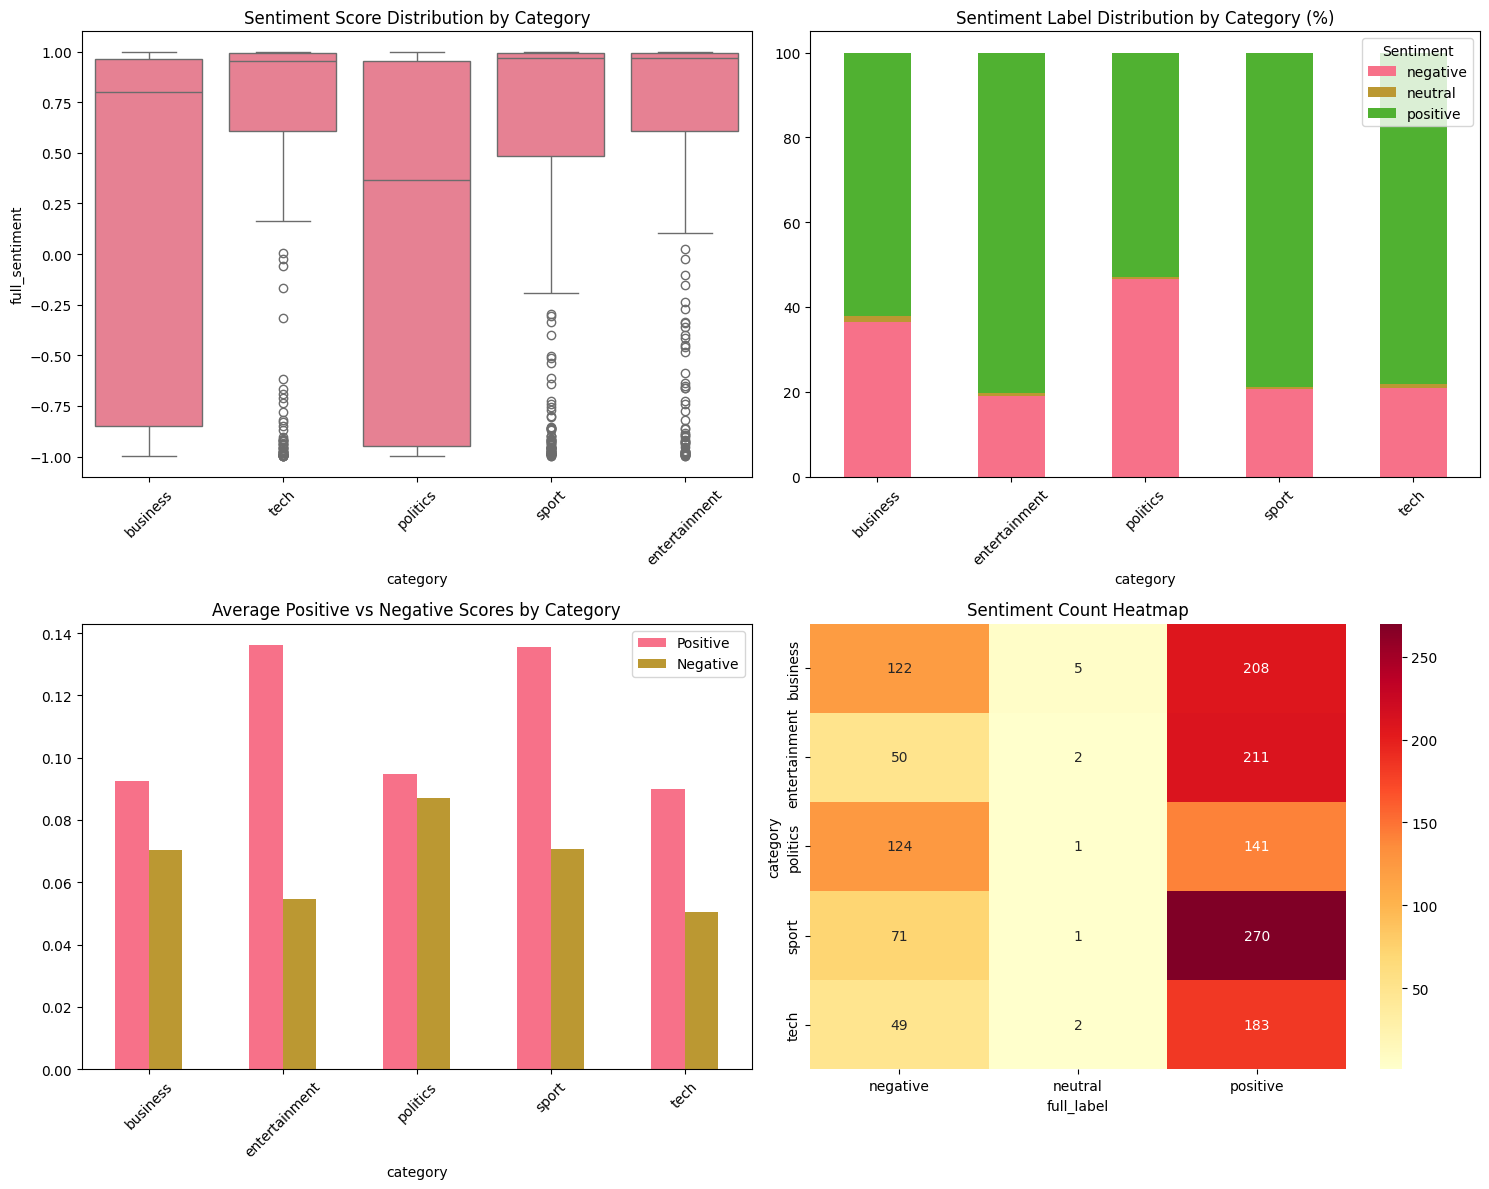

In [51]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

### Sentiment Analysis by Category — Interpretation

The charts show that sentiment varies across the five BBC News categories. Entertainment, Sports, and Technology have mostly positive articles, while Politics has a higher percentage of negative articles. Business contains a mixture of positive and negative articles.

Sentiment could be useful as an additional feature for news classification because different categories show different sentiment patterns. However, sentiment alone cannot accurately identify the category because positive and negative articles appear in every category. Combining sentiment with TF-IDF features may help improve classification, but we would need to test this to know for sure.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [52]:

# ============================================================
# MODULE 6: PREPARE FEATURES FOR CLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin

print("🔧 Preparing features for classification...")

# Use the actual columns in our BBC News dataset
required_columns = ['content', 'content_processed', 'category']

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

# Prepare dataset
model_df = df[required_columns].copy()
model_df['content'] = model_df['content'].fillna('').astype(str)
model_df['content_processed'] = (
    model_df['content_processed'].fillna('').astype(str)
)

# Add sentiment features using VADER
# Calculate from original article text
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

def get_sentiment_features(text):
    scores = sia.polarity_scores(text)
    return pd.Series({
        'full_sentiment': scores['compound'],
        'pos_score': scores['pos'],
        'neu_score': scores['neu'],
        'neg_score': scores['neg']
    })

sentiment_values = model_df['content'].apply(
    get_sentiment_features
)

model_df = pd.concat(
    [model_df, sentiment_values],
    axis=1
)

# Add text length features
model_df['char_length'] = model_df['content'].str.len()
model_df['word_count_feature'] = (
    model_df['content'].str.split().str.len()
)
model_df['processed_length'] = (
    model_df['content_processed'].str.len()
)

# Define input columns
feature_columns = [
    'content_processed',
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score',
    'char_length',
    'word_count_feature',
    'processed_length'
]

X = model_df[feature_columns]
y = model_df['category']

# Split data BEFORE fitting TF-IDF or scaling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n✅ Dataset prepared successfully!")
print(f"Total articles: {len(model_df)}")
print(f"Number of classes: {y.nunique()}")
print(f"Classes: {sorted(y.unique())}")

print("\n📈 Data split:")
print(f"Training set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")

print("\nFeature columns:")
print(feature_columns)


🔧 Preparing features for classification...

✅ Dataset prepared successfully!
Total articles: 1440
Number of classes: 5
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']

📈 Data split:
Training set: 1152 samples
Test set: 288 samples

Feature columns:
['content_processed', 'full_sentiment', 'pos_score', 'neu_score', 'neg_score', 'char_length', 'word_count_feature', 'processed_length']


In [53]:

# ============================================================
# MODULE 6: TRAIN AND EVALUATE MULTIPLE CLASSIFIERS
# ============================================================

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer

print("🤖 Training multiple classifiers...")

numeric_features = [
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score',
    'char_length',
    'word_count_feature',
    'processed_length'
]

# Create preprocessing for Logistic Regression and SVM
standard_preprocessor = ColumnTransformer(
    transformers=[
        (
            'tfidf',
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.8
            ),
            'content_processed'
        ),
        (
            'numeric',
            StandardScaler(),
            numeric_features
        )
    ]
)

# Naive Bayes requires nonnegative features
nb_preprocessor = ColumnTransformer(
    transformers=[
        (
            'tfidf',
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.8
            ),
            'content_processed'
        ),
        (
            'numeric',
            MinMaxScaler(),
            numeric_features
        )
    ]
)

# Define three classifiers
classifiers = {
    'Naive Bayes': Pipeline([
        ('preprocessor', nb_preprocessor),
        ('classifier', MultinomialNB())
    ]),

    'Logistic Regression': Pipeline([
        ('preprocessor', standard_preprocessor),
        ('classifier', LogisticRegression(
            random_state=42,
            max_iter=1000
        ))
    ]),

    'SVM': Pipeline([
        ('preprocessor', standard_preprocessor),
        ('classifier', SVC(
            random_state=42,
            probability=True
        ))
    ])
}

# Store results and trained models
results = {}
trained_models = {}

# Train and evaluate each model
for name, classifier in classifiers.items():

    print(f"\n🔄 Training {name}...")

    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)

    # Prediction probabilities
    if hasattr(classifier, 'predict_proba'):
        y_pred_proba = classifier.predict_proba(X_test)
    else:
        y_pred_proba = None

    # Calculate test accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation on training data only
    cv_scores = cross_val_score(
        classifier,
        X_train,
        y_train,
        cv=3,
        scoring='accuracy'
    )

    # Store evaluation results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(
        f"  📊 CV Score: {cv_scores.mean():.4f} "
        f"(+/- {cv_scores.std() * 2:.4f})"
    )

# Compare classifier performance
print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [
        results[name]['accuracy']
        for name in results.keys()
    ],
    'CV Mean': [
        results[name]['cv_mean']
        for name in results.keys()
    ],
    'CV Std': [
        results[name]['cv_std']
        for name in results.keys()
    ]
})

print(comparison_df.round(4).to_string(index=False))

# Identify the best model using cross-validation
best_model_name = comparison_df.loc[
    comparison_df['CV Mean'].idxmax(),
    'Model'
]

best_model = trained_models[best_model_name]

print(f"\n🥇 Best performing model: {best_model_name}")
print(
    f"Test accuracy: "
    f"{results[best_model_name]['accuracy']:.4f}"
)

print("\n✅ Model training and evaluation completed!")


🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.9375
  📊 CV Score: 0.9566 (+/- 0.0210)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.9306
  📊 CV Score: 0.9280 (+/- 0.0277)

🔄 Training SVM...
  ✅ Accuracy: 0.7500
  📊 CV Score: 0.6641 (+/- 0.0085)

🏆 CLASSIFIER COMPARISON
              Model  Test Accuracy  CV Mean  CV Std
        Naive Bayes         0.9375   0.9566  0.0105
Logistic Regression         0.9306   0.9280  0.0138
                SVM         0.7500   0.6641  0.0043

🥇 Best performing model: Naive Bayes
Test accuracy: 0.9375

✅ Model training and evaluation completed!


### Classification Model Comparison Summary

In this module, I trained and evaluated three machine learning models: Naive Bayes, Logistic Regression, and SVM. Naive Bayes performed the best, achieving 93.75% test accuracy and 95.66% cross-validation accuracy. Logistic Regression also performed well with 93.06% accuracy, while SVM had the lowest accuracy at 75%.

These results show that Naive Bayes was the most effective model for classifying the BBC News articles in this experiment. However, the models can still make mistakes when articles contain similar words or discuss overlapping topics.

📊 DETAILED EVALUATION: Naive Bayes

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.99      0.95        67
entertainment       0.98      0.92      0.95        53
     politics       0.96      0.89      0.92        53
        sport       0.91      1.00      0.95        68
         tech       0.95      0.85      0.90        47

     accuracy                           0.94       288
    macro avg       0.94      0.93      0.93       288
 weighted avg       0.94      0.94      0.94       288



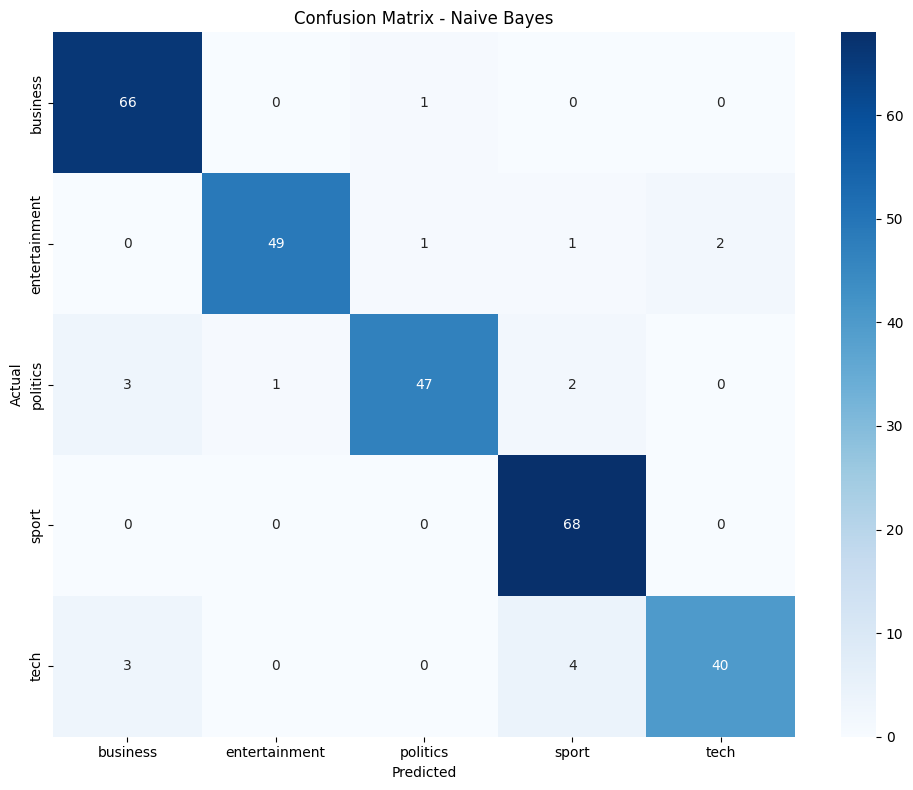

In [54]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

### Detailed Model Evaluation Summary

The confusion matrix shows that Naive Bayes performed well in classifying BBC News articles, achieving an accuracy of 93.75%. The model correctly classified all 68 sports articles in the test set. It also correctly classified 47 politics articles and 40 technology articles.

However, some articles were classified incorrectly, especially when topics overlapped. This shows that Naive Bayes is effective for news classification, but it is not perfect. Overall, the results suggest that the model can help NewsBot automatically organize articles into different categories.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [55]:

import pandas as pd
import spacy

# Load spaCy English model if not already loaded
if 'nlp' not in globals():
    nlp = spacy.load("en_core_web_sm")

# Extract named entities using spaCy
def extract_entities(text):
    """
    Extract named entities using spaCy.
    """
    if pd.isna(text) or not str(text).strip():
        return []

    # Process text with spaCy
    doc = nlp(str(text))

    # Extract named entities
    entities = []

    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'description': spacy.explain(ent.label_)
        })

    return entities


# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():

    # Use the correct dataset column: content
    entities = extract_entities(row['content'])

    # Use the correct article ID column: ArticleId
    article_id = row['ArticleId']

    # Store entities for this article
    article_entities.append({
        'article_id': article_id,
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        all_entities.append({
            'text': entity['text'],
            'label': entity['label'],
            'description': entity['description'],
            'article_id': article_id,
            'category': row['category']
        })

print("\n✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(
    all_entities,
    columns=['text', 'label', 'description',
             'article_id', 'category']
)

if not entities_df.empty:

    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")

    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))

else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

print("\n✅ NER analysis completed successfully!")


🔍 Extracting named entities...

✅ Entity extraction complete!
📊 Total entities found: 40803
📰 Articles processed: 1440

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business

✅ NER analysis completed successfully!


In this module, I used spaCy to extract named entities from 1,440 BBC News articles. The system identified 40,803 entity mentions across 18 different types, including people, organizations, locations, dates, and money. This shows how Named Entity Recognition can help NewsBot identify important information in news articles. However, some entities may be incorrectly identified, so the results are not always perfect.

📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8523
PERSON         7802
CARDINAL       5965
GPE            5433
ORG            4288
NORP           2666
MONEY          1710
ORDINAL        1609
PERCENT        1242
TIME            582
LOC             489
QUANTITY        191
FAC              88
PRODUCT          82
LANGUAGE         50
EVENT            42
LAW              33
WORK_OF_ART       8
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1031  2398      3   10  1543         1   15  166    906   
entertainment      1068  1672     11   15   773         9    4   63    343   
politics            804  1322     22   23   933        10    4  120    222   
sport              1780  1966      5   39  1482        11    5   33     43   
tech               1282  1165      1    1   702     

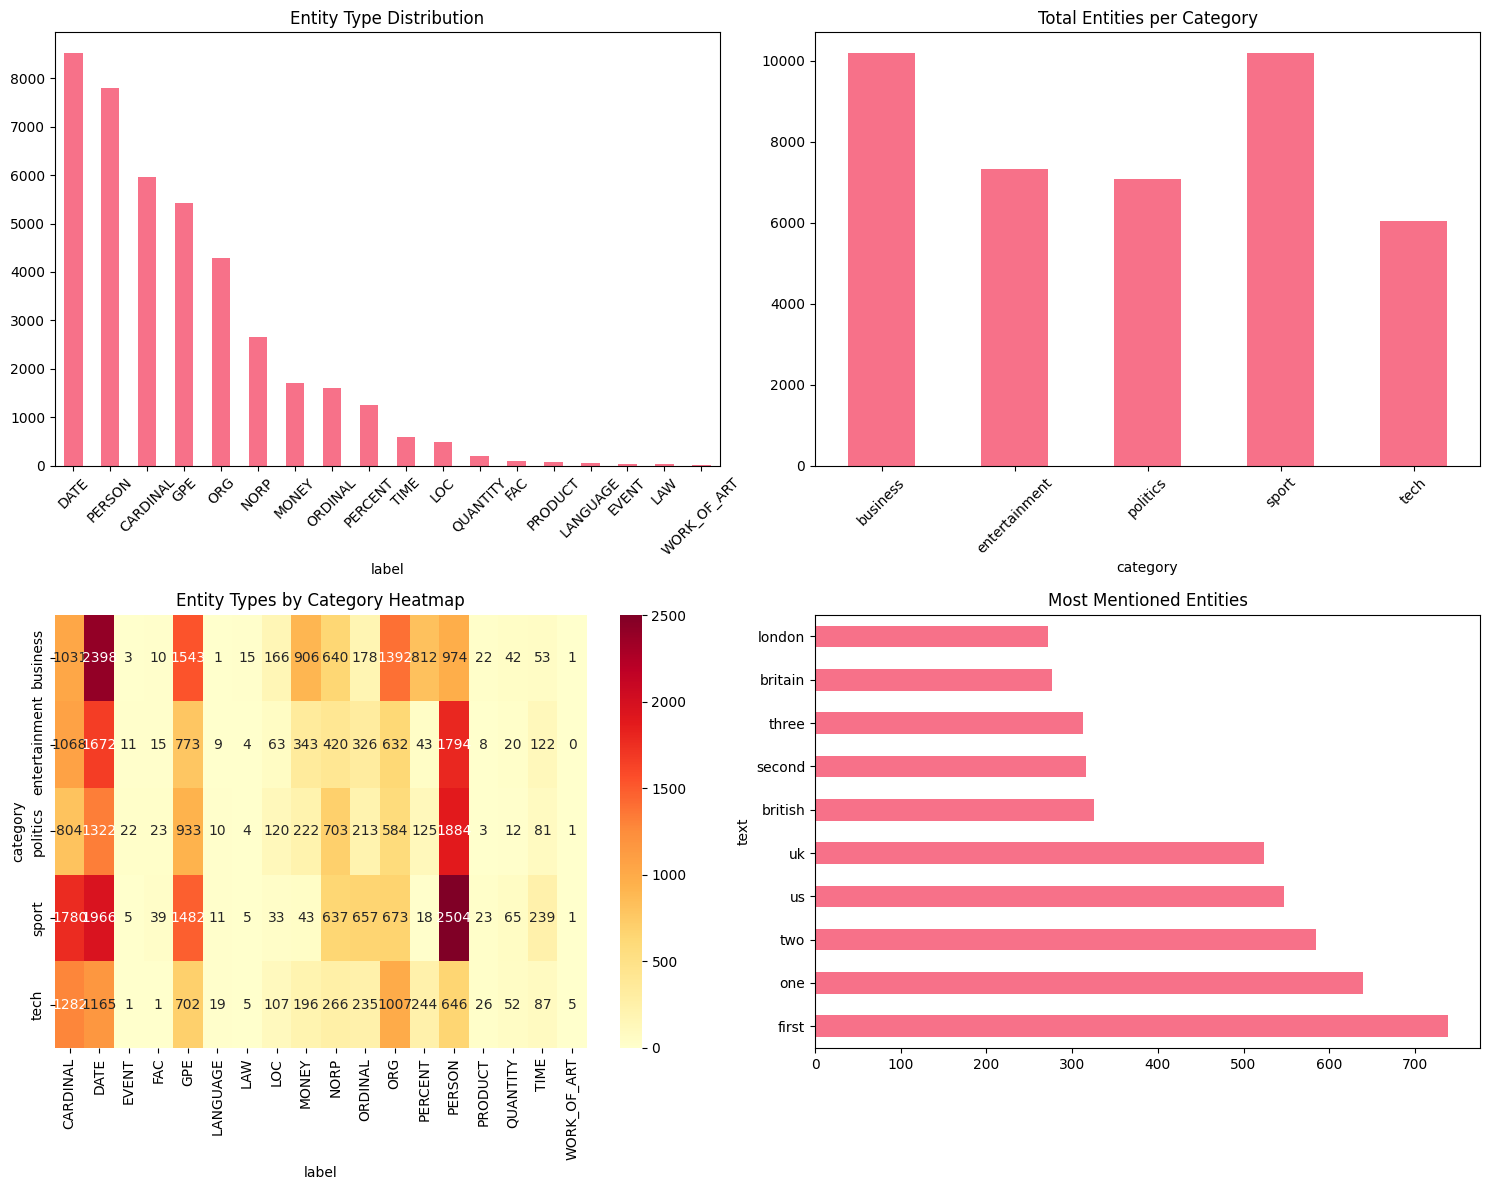

In [56]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

In this section, I analyzed the named entities extracted from BBC News articles. The results showed that different news categories contain different types of entities. Sports articles had many mentions of people, while Politics articles included people and locations. Technology articles also contained many organization names. The most frequent entities included words such as "first," "one," "US," and "UK." These results show how Named Entity Recognition can help NewsBot identify important information and compare patterns across news categories.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [57]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# COMPREHENSIVE ANALYSIS DASHBOARD
# ============================================================

import pandas as pd
import numpy as np

# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining:
    - Dataset overview
    - Classification performance
    - Sentiment patterns
    - Named entity recognition
    - Linguistic features
    - Business recommendations
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # --------------------------------------------------------
    # 1. DATASET OVERVIEW
    # --------------------------------------------------------

    # Use the actual text column in the dataset
    text_column = 'content'

    article_text = df[text_column].fillna('').astype(str)

    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': article_text.str.len().mean(),
        'avg_words_per_article': article_text.str.split().str.len().mean()
    }

    # --------------------------------------------------------
    # 2. CLASSIFICATION PERFORMANCE
    # --------------------------------------------------------

    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {
            name: results[name]['accuracy']
            for name in results.keys()
        }
    }

    # --------------------------------------------------------
    # 3. SENTIMENT ANALYSIS
    # --------------------------------------------------------

    sentiment_by_cat = (
        sentiment_df.groupby('category')['full_sentiment']
        .mean()
        .to_dict()
    )

    insights['sentiment_insights'] = {
        'most_positive_category': max(
            sentiment_by_cat,
            key=sentiment_by_cat.get
        ),
        'most_negative_category': min(
            sentiment_by_cat,
            key=sentiment_by_cat.get
        ),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # --------------------------------------------------------
    # 4. NAMED ENTITY RECOGNITION
    # --------------------------------------------------------

    if not entities_df.empty:

        entity_by_cat = (
            entities_df.groupby('category')
            .size()
            .to_dict()
        )

        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': (
                entities_df['text']
                .value_counts()
                .head(5)
                .to_dict()
            )
        }

    # --------------------------------------------------------
    # 5. LINGUISTIC PATTERNS
    # --------------------------------------------------------

    linguistic = {
        'average_words_per_article':
            insights['dataset_overview']['avg_words_per_article'],
        'average_characters_per_article':
            insights['dataset_overview']['avg_article_length']
    }

    # Include POS analysis if it was created earlier
    if 'pos_df' in globals() and not pos_df.empty:

        linguistic['pos_analysis_available'] = True

        pos_columns = pos_df.select_dtypes(
            include='number'
        ).columns.tolist()

        if pos_columns:
            linguistic['average_pos_proportions'] = (
                pos_df[pos_columns].mean().to_dict()
            )

    else:
        linguistic['pos_analysis_available'] = False

    insights['linguistic_patterns'] = linguistic

    # --------------------------------------------------------
    # 6. BUSINESS RECOMMENDATIONS
    # --------------------------------------------------------

    recommendations = []

    # Classification recommendations
    best_accuracy = insights[
        'classification_performance'
    ]['best_accuracy']

    if best_accuracy > 0.8:
        recommendations.append(
            "High classification accuracy achieved. "
            "NewsBot shows promise for automatic news categorization, "
            "but further testing is needed before deployment."
        )
    else:
        recommendations.append(
            "Classification accuracy needs improvement. "
            "Consider additional training data or feature engineering."
        )

    # Sentiment recommendations
    pos_cat = insights[
        'sentiment_insights'
    ]['most_positive_category']

    neg_cat = insights[
        'sentiment_insights'
    ]['most_negative_category']

    recommendations.append(
        f"{pos_cat.title()} has the highest average sentiment score. "
        "This may help NewsBot identify more positive news content."
    )

    recommendations.append(
        f"{neg_cat.title()} has the lowest average sentiment score. "
        "Sentiment results should be interpreted carefully."
    )

    # Entity recommendations
    if insights['entity_insights']:
        recommendations.append(
            "Named Entity Recognition can help NewsBot identify "
            "people, organizations, locations, and dates for "
            "improved news searching and organization."
        )

    # Linguistic recommendations
    recommendations.append(
        "Text length and grammatical patterns can provide "
        "additional information for analyzing news articles."
    )

    insights['business_recommendations'] = recommendations

    return insights


# ============================================================
# GENERATE COMPREHENSIVE ANALYSIS
# ============================================================

print("📊 Generating comprehensive analysis...")

analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")

print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)


# ------------------------------------------------------------
# DATASET OVERVIEW
# ------------------------------------------------------------

print("\n📊 DATASET OVERVIEW:")

overview = analysis_results['dataset_overview']

print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(
    f"  Average Article Length: "
    f"{overview['avg_article_length']:.0f} characters"
)
print(
    f"  Average Words per Article: "
    f"{overview['avg_words_per_article']:.0f} words"
)

print("\n  Articles by Category:")

for category, count in overview['category_distribution'].items():
    print(f"    {category}: {count}")


# ------------------------------------------------------------
# CLASSIFICATION PERFORMANCE
# ------------------------------------------------------------

print("\n🤖 CLASSIFICATION PERFORMANCE:")

perf = analysis_results['classification_performance']

print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print("\n  Model Comparison:")

for model, accuracy in perf['model_comparison'].items():
    print(f"    {model}: {accuracy:.4f}")


# ------------------------------------------------------------
# SENTIMENT INSIGHTS
# ------------------------------------------------------------

print("\n😊 SENTIMENT INSIGHTS:")

sent = analysis_results['sentiment_insights']

print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

print("\n  Average Sentiment by Category:")

for category, score in sent['sentiment_by_category'].items():
    print(f"    {category}: {score:.4f}")


# ------------------------------------------------------------
# ENTITY INSIGHTS
# ------------------------------------------------------------

if analysis_results['entity_insights']:

    print("\n🔍 ENTITY INSIGHTS:")

    ent = analysis_results['entity_insights']

    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

    print("\n  Top 5 Most Mentioned Entities:")

    for entity, count in ent['most_mentioned_entities'].items():
        print(f"    {entity}: {count}")


# ------------------------------------------------------------
# LINGUISTIC PATTERNS
# ------------------------------------------------------------

print("\n📝 LINGUISTIC PATTERNS:")

ling = analysis_results['linguistic_patterns']

print(
    f"  Average Words per Article: "
    f"{ling['average_words_per_article']:.0f}"
)

print(
    f"  Average Characters per Article: "
    f"{ling['average_characters_per_article']:.0f}"
)

print(
    f"  POS Analysis Available: "
    f"{ling['pos_analysis_available']}"
)


# ------------------------------------------------------------
# BUSINESS RECOMMENDATIONS
# ------------------------------------------------------------

print("\n💡 BUSINESS RECOMMENDATIONS:")

for i, rec in enumerate(
    analysis_results['business_recommendations'], 1
):
    print(f"  {i}. {rec}")


print("\n" + "=" * 60)
print("✅ COMPREHENSIVE ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)


📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1440
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2234 characters
  Average Words per Article: 385 words

  Articles by Category:
    sport: 342
    business: 335
    politics: 266
    entertainment: 263
    tech: 234

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Naive Bayes
  Best Accuracy: 0.9375

  Model Comparison:
    Naive Bayes: 0.9375
    Logistic Regression: 0.9306
    SVM: 0.7500

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3902

  Average Sentiment by Category:
    business: 0.2381
    entertainment: 0.5900
    politics: 0.0541
    sport: 0.5492
    tech: 0.5330

🔍 ENTITY INSIGHTS:
  Total Entities: 40803
  Unique Entities: 12071
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERC

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [58]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify article category"""
        # 🚀 YOUR CODE HERE: Implement classification
        # Transform text to features
        features = self.vectorizer.transform([processed_text])

        # Add dummy features for sentiment and length (in production, calculate these)
        dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
        features_combined = np.hstack([features.toarray(), dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [59]:

# Test the complete NewsBot Intelligence System
import pandas as pd
import numpy as np

print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': (
            "Microsoft Corporation announced today the acquisition "
            "of an artificial intelligence startup for $2 billion. "
            "CEO Satya Nadella said the deal will strengthen Microsoft's "
            "position in the AI market and enhance cloud computing services."
        )
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': (
            "The Los Angeles Lakers defeated the Boston Celtics "
            "108-102 in overtime to win the NBA championship. "
            "LeBron James scored 35 points and was named Finals MVP."
        )
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': (
            "Scientists at the United Nations released a climate "
            "report showing accelerating global warming. "
            "The report warns that immediate action is needed "
            "to prevent environmental changes."
        )
    }
]

# Use the same feature columns used during model training
feature_columns = [
    'content_processed',
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score',
    'char_length',
    'word_count_feature',
    'processed_length'
]

def prepare_test_article(title, content):
    """Prepare one article using the training feature structure."""

    full_text = f"{title} {content}"

    # Use the existing text preprocessing function if available
    if 'preprocess_text' in globals():
        processed = preprocess_text(full_text)
    else:
        processed = full_text.lower()

    processed = str(processed)

    # Sentiment analysis
    scores = sia.polarity_scores(full_text)

    # Build input row
    article_features = pd.DataFrame([{
        'content_processed': processed,
        'full_sentiment': scores['compound'],
        'pos_score': scores['pos'],
        'neu_score': scores['neu'],
        'neg_score': scores['neg'],
        'char_length': len(full_text),
        'word_count_feature': len(full_text.split()),
        'processed_length': len(processed)
    }])

    return article_features[feature_columns]


# Test each article
for i, article in enumerate(test_articles, 1):

    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 50)

    title = article['title']
    content = article['content']

    print(f"Title: {title}")

    try:
        # Prepare the eight input features
        X_new = prepare_test_article(title, content)

        # Predict using the trained model
        predicted_category = best_model.predict(X_new)[0]

        print(f"\n🏷️ Predicted Category: {predicted_category}")

        # Show probabilities if available
        if hasattr(best_model, 'predict_proba'):
            probabilities = best_model.predict_proba(X_new)[0]
            classes = best_model.classes_

            print("\n📊 Category Probabilities:")
            for category, probability in sorted(
                zip(classes, probabilities),
                key=lambda x: x[1],
                reverse=True
            ):
                print(f"  {category}: {probability:.3f}")

            print(
                f"\n🎯 Confidence: "
                f"{max(probabilities):.2%}"
            )

        # Sentiment
        sentiment = analyze_sentiment(f"{title} {content}")

        print(
            f"\n😊 Sentiment: "
            f"{sentiment['sentiment_label']} "
            f"(score: {sentiment['compound']:.3f})"
        )

        # Named entities
        entities = extract_entities(f"{title} {content}")

        if entities:
            print(f"\n🔍 Entities Found ({len(entities)}):")

            for entity in entities[:5]:
                print(
                    f"  {entity['text']} "
                    f"({entity['label']})"
                )
        else:
            print("\n🔍 No entities detected")

        print("\n✅ Article processed successfully!")

    except Exception as e:
        print(f"\n❌ Error processing article: {e}")

print("\n" + "=" * 60)
print("🏁 NewsBot test run finished.")


🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
--------------------------------------------------
Title: Microsoft Acquires AI Startup for $2 Billion

🏷️ Predicted Category: tech

📊 Category Probabilities:
  tech: 0.414
  business: 0.294
  sport: 0.104
  politics: 0.100
  entertainment: 0.088

🎯 Confidence: 41.41%

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG)
  $2 Billion (MONEY)
  Microsoft Corporation (ORG)
  today (DATE)
  $2 billion (MONEY)

✅ Article processed successfully!

📰 TEST ARTICLE 2
--------------------------------------------------
Title: Lakers Win Championship in Overtime Thriller

🏷️ Predicted Category: sport

📊 Category Probabilities:
  sport: 0.803
  entertainment: 0.132
  business: 0.031
  politics: 0.018
  tech: 0.017

🎯 Confidence: 80.30%

😊 Sentiment: positive (score: 0.893)

🔍 Entities Found (6):
  Boston Celtics (ORG)
  108 (CARDINAL)
  NBA (ORG)
  LeBron James (PERSON)
  35 (CARDINAL)

✅ Article processed suc

I tested the NewsBot system using three articles about technology, sports, and climate change. All three articles were processed successfully. The Microsoft article was classified as Tech with 41.41% confidence, while the Lakers article was classified as Sport with 80.30% confidence. The climate change article was classified as Business with only 36.28% confidence.

I noticed that the system performed better when the article clearly belonged to one category. The climate change article showed a limitation because its topic did not fit easily into the available categories. I also noticed that the sentiment analyzer labeled all three articles as positive, even though the climate change article discussed serious environmental concerns. This helped me understand that NLP models can produce results that need human review. In the future, I would improve the system by testing more articles, adding more training examples, and reviewing predictions with low confidence.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*